# Analysis
**Daphnne Chacon, INFO-4617**

Three questions about the 31 public figures in `data/clean/`:

1. Who had the biggest disruption to their Wikipedia attention after the Epstein files were released?
2. Are people mentioned more often in the files disrupted more?
3. Do their articles mention the Epstein files now, or were those mentions removed?

Run this after `02_collect_and_clean.ipynb`. Figures are saved to `figures/`.

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Reads the clean data from the repo folder if it is there, otherwise from GitHub
LOCAL = Path("../data/clean")
# Change REPO_NAME to your new repository's name
GITHUB_USER = "daphnnec"
REPO_NAME = "epstein-files-wikipedia-attention"
GITHUB = f"https://raw.githubusercontent.com/{GITHUB_USER}/{REPO_NAME}/main/data/clean"

def read(name, **kwargs):
    path = LOCAL / name
    return pd.read_csv(path if path.exists() else f"{GITHUB}/{name}", **kwargs)

people = read("people.csv")
daily = read("pageviews_daily.csv", parse_dates=["date"])

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

# The three big public releases
EVENTS = {
    "House Oversight emails": pd.Timestamp("2025-11-12"),
    "DOJ first release":      pd.Timestamp("2025-12-19"),
    "DOJ 3 million pages":    pd.Timestamp("2026-01-30"),
}
BASELINE = (pd.Timestamp("2025-09-13"), pd.Timestamp("2025-11-11"))   # 60 days before the first release
WINDOW = 14   # days after each release

print(len(people), "people |", len(daily), "daily rows |",
      daily["date"].min().date(), "to", daily["date"].max().date())

31 people | 14539 daily rows | 2025-08-01 to 2026-11-12


## 1. Who had the biggest disruption?

For each person, the **baseline** is their median daily views in the 60 days before the first release. The **disruption** for each release is their average daily views in the 14 days starting that day, divided by the baseline. A disruption of 10 means ten times their normal attention.

In [13]:
baseline = (daily[daily["date"].between(*BASELINE)]
            .groupby("person")["views"].median()
            .clip(lower=1)                 # avoid dividing by zero
            .rename("baseline_views"))

results = people.set_index("person").join(baseline)
no_views = daily.groupby("person")["views"].sum().loc[lambda s: s == 0].index
if len(no_views):
    print("Dropped (no pageviews found):", ", ".join(no_views))
results = results.drop(no_views)
for name, day in EVENTS.items():
    window = daily[daily["date"].between(day, day + pd.Timedelta(days=WINDOW - 1))]
    results[name] = window.groupby("person")["views"].mean() / results["baseline_views"]

event_cols = list(EVENTS)
results["max_disruption"] = results[event_cols].max(axis=1)
results["biggest_release"] = results[event_cols].idxmax(axis=1)
results = results.sort_values("max_disruption", ascending=False)

results[["baseline_views"] + event_cols + ["max_disruption", "biggest_release"]].round(1)

,baseline_views,House Oversight emails,DOJ first release,DOJ 3 million pages,max_disruption,biggest_release
person,,,,,,
Larry Summers,65.0,14.1,40.5,128.3,128.3,DOJ 3 million pages
Kathryn Ruemmler,67.0,89.3,8.7,127.5,127.5,DOJ 3 million pages
Casey Wasserman,218.0,1.3,1.1,74.9,74.9,DOJ 3 million pages
Peter Mandelson,1274.0,2.3,0.8,70.8,70.8,DOJ 3 million pages
Thorbjørn Jagland,62.5,11.4,2.1,50.1,50.1,DOJ 3 million pages
Steve Tisch,366.5,1.5,0.9,46.4,46.4,DOJ 3 million pages
Joi Ito,98.5,8.6,1.7,44.5,44.5,DOJ 3 million pages
Mette-Marit,1050.5,0.9,1.8,30.5,30.5,DOJ 3 million pages
Les Wexner,1747.5,3.2,4.7,24.1,24.1,DOJ 3 million pages


In [14]:
print("Which release caused each person's biggest disruption:")
print(results["biggest_release"].value_counts().to_string())
print()
print("Median disruption across people, by release:")
print(results[event_cols].median().round(2).to_string())

Which release caused each person's biggest disruption:
biggest_release
DOJ 3 million pages       29
House Oversight emails     2

Median disruption across people, by release:
House Oversight emails     2.26
DOJ first release          1.58
DOJ 3 million pages       13.66


## 2. Are people mentioned more in the files disrupted more?

I compare the number of emails that mention each person with their biggest disruption, using a Spearman rank correlation (which only asks whether more mentions tends to go with more disruption, so a few huge values can't dominate it).

In [15]:
rho = results["email_mentions"].corr(results["max_disruption"], method="spearman")
print(f"Spearman correlation between email mentions and biggest disruption: {rho:.2f}")

median_mentions = results["email_mentions"].median()
results["mention_group"] = np.where(results["email_mentions"] > median_mentions,
                                    "more mentions", "fewer mentions")
print(f"\nSplit at the median of {median_mentions:.0f} emails:")
print(results.groupby("mention_group")["max_disruption"].agg(["count", "median"]).round(1).to_string())

Spearman correlation between email mentions and biggest disruption: 0.08

Split at the median of 4387 emails:
                count  median
mention_group                
fewer mentions     16     8.4
more mentions      15    15.4


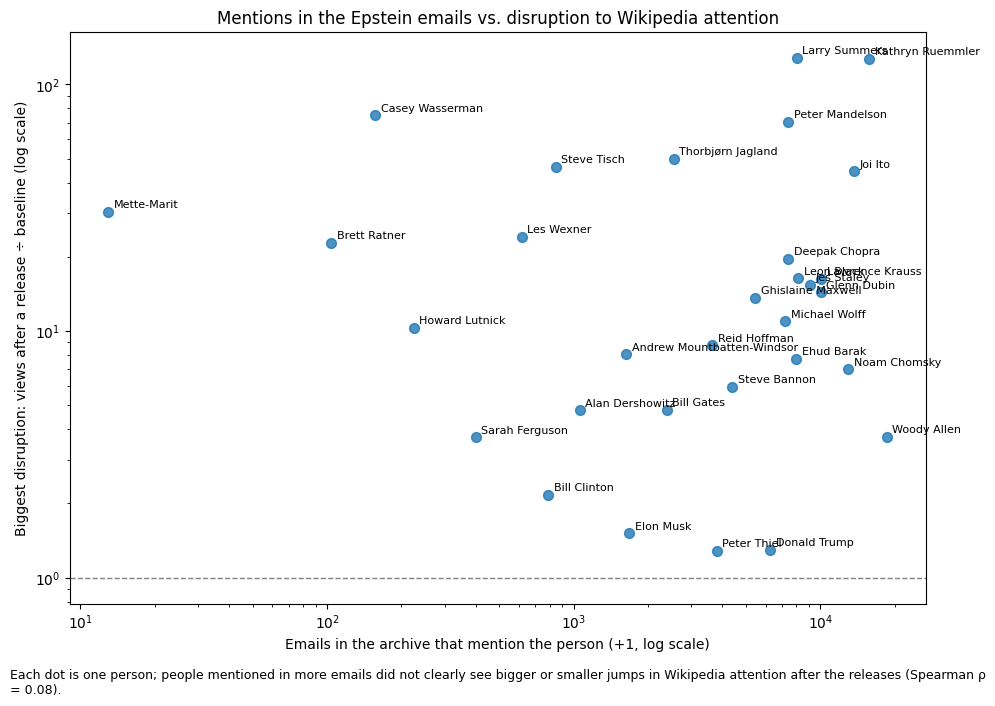

Each dot is one person; people mentioned in more emails did not clearly see bigger or smaller jumps in Wikipedia attention after the releases (Spearman ρ = 0.08).


In [16]:
fig, ax = plt.subplots(figsize=(10, 7))
x = results["email_mentions"] + 1          # +1 so people with zero mentions still appear on a log scale
y = results["max_disruption"]
ax.scatter(x, y, s=50, alpha=0.8)
for person, xi, yi in zip(results.index, x, y):
    ax.annotate(person, (xi, yi), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_yscale("log")
ax.axhline(1, color="gray", linestyle="--", linewidth=1)
ax.set_title("Mentions in the Epstein emails vs. disruption to Wikipedia attention")
ax.set_xlabel("Emails in the archive that mention the person (+1, log scale)")
ax.set_ylabel("Biggest disruption: views after a release ÷ baseline (log scale)")
trend = ("tended to see bigger" if rho > 0.3 else
         "tended to see smaller" if rho < -0.3 else "did not clearly see bigger or smaller")
caption = (f"Each dot is one person; people mentioned in more emails {trend} jumps in "
           f"Wikipedia attention after the releases (Spearman ρ = {rho:.2f}).")
fig.text(0.01, 0.005, caption, fontsize=9, wrap=True)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIGURES / "mentions_vs_disruption.png", dpi=150)
plt.show()
print(caption)

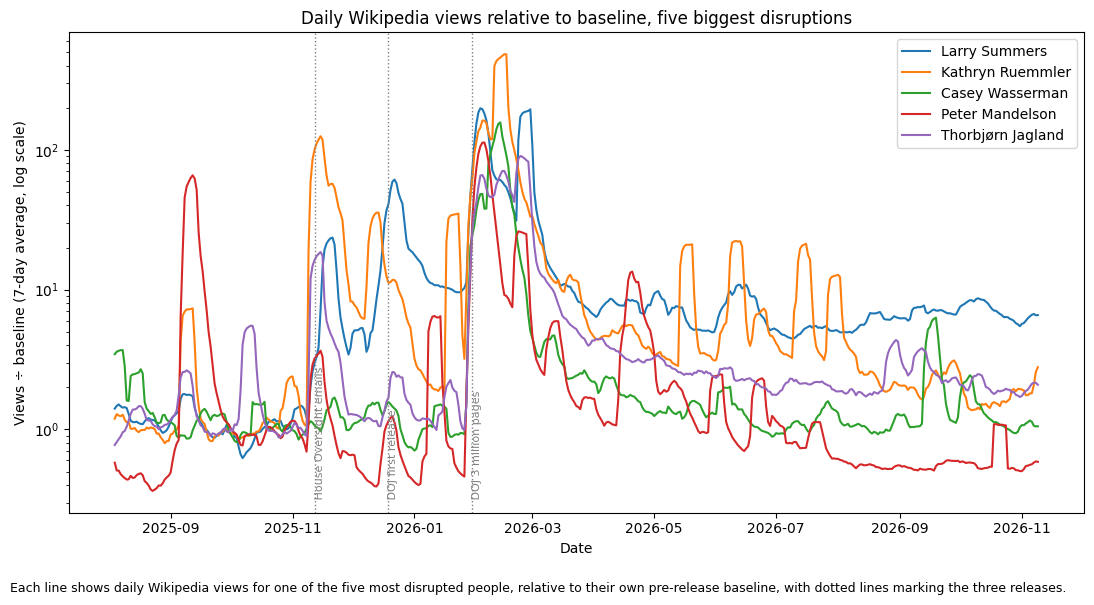

Each line shows daily Wikipedia views for one of the five most disrupted people, relative to their own pre-release baseline, with dotted lines marking the three releases.


In [17]:
top = results.head(5).index
fig, ax = plt.subplots(figsize=(11, 6))
for person in top:
    d = daily[daily["person"] == person].set_index("date")["views"]
    rel = (d / results.loc[person, "baseline_views"]).rolling(7, center=True).mean()
    ax.plot(rel.index, rel.values, label=person)
for name, day in EVENTS.items():
    ax.axvline(day, color="gray", linestyle=":", linewidth=1)
    ax.text(day, 0.02, " " + name, rotation=90, va="bottom", fontsize=8, color="gray",
            transform=ax.get_xaxis_transform())
ax.set_yscale("log")
ax.set_title("Daily Wikipedia views relative to baseline, five biggest disruptions")
ax.set_xlabel("Date")
ax.set_ylabel("Views ÷ baseline (7-day average, log scale)")
ax.legend()
caption2 = ("Each line shows daily Wikipedia views for one of the five most disrupted people, "
            "relative to their own pre-release baseline, with dotted lines marking the three releases.")
fig.text(0.01, 0.005, caption2, fontsize=9, wrap=True)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIGURES / "top5_timeline.png", dpi=150)
plt.show()
print(caption2)

## 3. Do their articles mention the Epstein files now, or were they scrubbed?

I count how many times "Epstein" appears in each article just before the first release, on March 1, 2026, and today. An article counts as **reduced** if it mentioned Epstein in March 2026 and now mentions him less than half as often.

In [18]:
art = results[["epstein_mentions_before", "epstein_mentions_mar2026",
               "epstein_mentions_now", "epstein_heading_now"]].copy()

def status(row):
    b, m, n = row["epstein_mentions_before"], row["epstein_mentions_mar2026"], row["epstein_mentions_now"]
    if pd.isna(n):
        return "no article"
    if n == 0:
        return "no mention now"
    if pd.notna(m) and m > 0 and n < 0.5 * m:
        return "reduced since March"
    if pd.notna(b) and n > b:
        return "added since release"
    return "about the same"

art["status"] = art.apply(status, axis=1)
print(art["status"].value_counts().to_string())
art.sort_values("epstein_mentions_now", ascending=False)

status
added since release    29
about the same          1
no mention now          1


,epstein_mentions_before,epstein_mentions_mar2026,epstein_mentions_now,epstein_heading_now,status
person,,,,,
Ghislaine Maxwell,318,326,383,True,added since release
Leon Black,88,90,155,True,added since release
Andrew Mountbatten-Windsor,154,108,125,True,about the same
Jes Staley,80,95,122,True,added since release
Bill Gates,41,76,107,True,added since release
Peter Mandelson,33,92,101,True,added since release
Les Wexner,45,78,89,True,added since release
Sarah Ferguson,41,77,81,True,added since release
Kathryn Ruemmler,9,44,71,True,added since release


## Summary for the README

In [19]:
# Plain-language summary of the main numbers, for the README's Findings section
top3 = results.head(3)
print(f"- Biggest disruptions: " + "; ".join(
    f"{p} ({r.max_disruption:.0f} times baseline, {r.biggest_release})" for p, r in top3.iterrows()))
print(f"- The release that most often caused a person's biggest disruption: "
      f"{results['biggest_release'].value_counts().idxmax()}")
print(f"- Spearman correlation between email mentions and biggest disruption: {rho:.2f}")
counts = art["status"].value_counts()
print(f"- Articles now mentioning Epstein: {(art['epstein_mentions_now'] > 0).sum()} of {len(art)}; "
      f"with an Epstein section heading: {int(art['epstein_heading_now'].sum())}; "
      f"reduced since March 2026: {counts.get('reduced since March', 0)}")

- Biggest disruptions: Larry Summers (128 times baseline, DOJ 3 million pages); Kathryn Ruemmler (127 times baseline, DOJ 3 million pages); Casey Wasserman (75 times baseline, DOJ 3 million pages)
- The release that most often caused a person's biggest disruption: DOJ 3 million pages
- Spearman correlation between email mentions and biggest disruption: 0.08
- Articles now mentioning Epstein: 30 of 31; with an Epstein section heading: 25; reduced since March 2026: 0
